In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


# Experiment: Gradient Descent, SGD, Momentum and Adam Comparison

1. Student Performance Prediction — Gradient Descent vs SGD

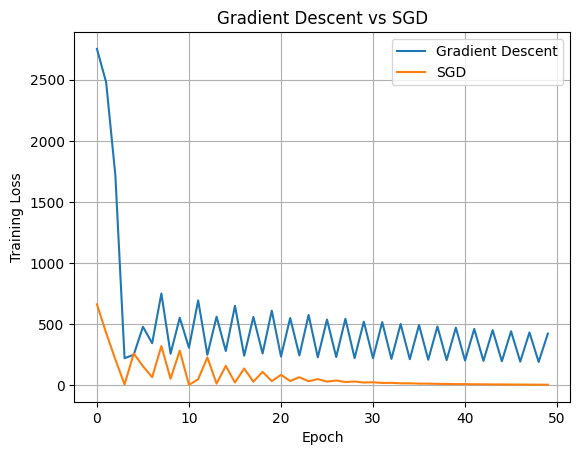

Final losses:
Gradient Descent : 421.437255859375
SGD : 2.7425856590270996


In [7]:
np.random.seed(42)
tf.random.set_seed(42)

X = np.random.rand(200, 2).astype("float32")
y = (50 * X[:, 0] + 30 * X[:, 1] + 10).astype("float32")

def create_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

base = create_model()
initial_weights = base.get_weights()

optimizers = {
    "Gradient Descent": tf.keras.optimizers.SGD(learning_rate=0.01),
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01)
}

losses = {}

for name, optimizer in optimizers.items():
    model = create_model()
    model.set_weights(initial_weights)

    model.compile(optimizer=optimizer, loss="mse")

    batch = len(X) if name == "Gradient Descent" else 16

    history = model.fit(
        X, y, epochs=50, batch_size=batch, verbose=0
    )

    losses[name] = np.array(history.history["loss"])

for name, loss in losses.items():
    plt.plot(loss, label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Gradient Descent vs SGD")
plt.legend()
plt.grid()
plt.show()

print("Final losses:")
for name, loss in losses.items():
    print(name, ":", loss[-1])

2. House Price Prediction — Effect of Learning Rate

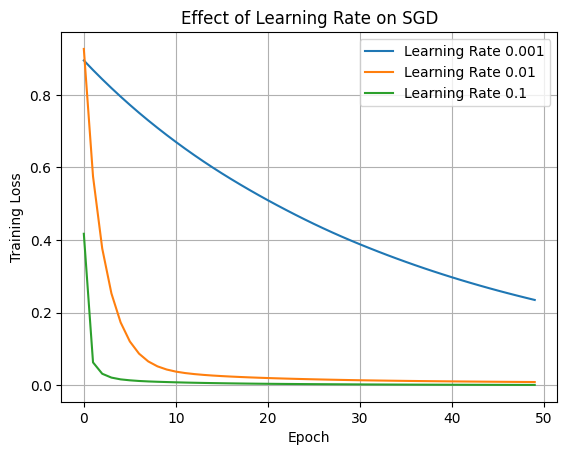

Learning Rate 0.001: Final Loss = 0.235170
Learning Rate 0.01: Final Loss = 0.009134
Learning Rate 0.1: Final Loss = 0.001176


In [8]:
np.random.seed(42)
tf.random.set_seed(42)

X = np.random.rand(300, 3).astype("float32")
y = (200 + 150 * X[:, 0] + 100 * X[:, 1]
     - 50 * X[:, 2]).astype("float32")

X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)
y = (y - y.mean()) / y.std()

learning_rates = [0.001, 0.01, 0.1]
losses = {}

for lr in learning_rates:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=lr),
        loss="mse"
    )

    history = model.fit(X, y, epochs=50, batch_size=32, verbose=0)
    losses[lr] = np.array(history.history["loss"])

for lr, loss in losses.items():
    plt.plot(loss, label=f"Learning Rate {lr}")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Effect of Learning Rate on SGD")
plt.legend()
plt.grid()
plt.show()

for lr, loss in losses.items():
    print(f"Learning Rate {lr}: Final Loss = {loss[-1]:.6f}")

3. Handwritten Digit Classification — SGD vs Momentum

SGD Test Accuracy: 0.8295
Momentum Test Accuracy: 0.9005


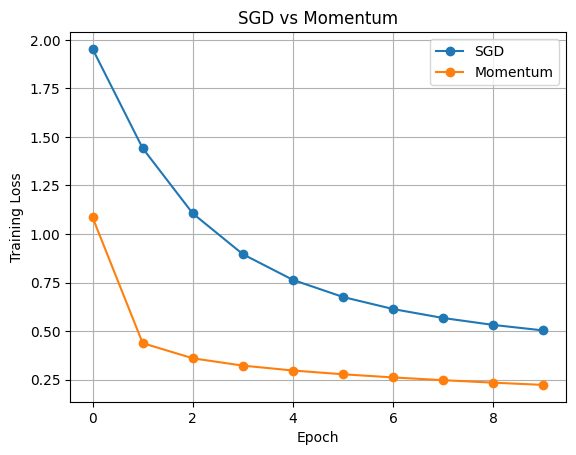

In [9]:
np.random.seed(42)
tf.random.set_seed(42)

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train[:10000].astype("float32") / 255.0
y_train = y_train[:10000]

X_test = X_test[:2000].astype("float32") / 255.0
y_test = y_test[:2000]

def create_digit_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

base = create_digit_model()
initial_weights = base.get_weights()

optimizers = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),
    "Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    )
}

losses = {}

for name, optimizer in optimizers.items():
    model = create_digit_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        epochs=10, batch_size=128, verbose=0
    )

    losses[name] = np.array(history.history["loss"])

    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    print(f"{name} Test Accuracy: {test_acc:.4f}")

for name, loss in losses.items():
    plt.plot(loss, marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Momentum")
plt.legend()
plt.grid()
plt.show()

4. Disease Risk Classification — Gradient Descent vs Adam

Gradient Descent Test Accuracy: 0.7700
Adam Test Accuracy: 0.9200


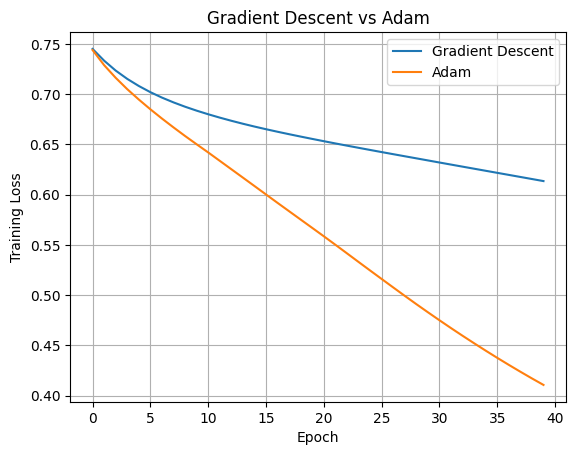

In [10]:
np.random.seed(42)
tf.random.set_seed(42)

X = np.random.rand(500, 4).astype("float32")
score = X[:, 0] + X[:, 1] * 0.8 + X[:, 2] * 0.5 - X[:, 3] * 0.3
y = (score > np.median(score)).astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def create_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

base = create_model()
initial_weights = base.get_weights()

optimizers = {
    "Gradient Descent": tf.keras.optimizers.SGD(learning_rate=0.01),
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.001)
}

losses = {}

for name, optimizer in optimizers.items():
    model = create_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        epochs=40, batch_size=32, verbose=0
    )

    losses[name] = np.array(history.history["loss"])

    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    print(f"{name} Test Accuracy: {test_acc:.4f}")

for name, loss in losses.items():
    plt.plot(loss, label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Gradient Descent vs Adam")
plt.legend()
plt.grid()
plt.show()

5. Sales Forecasting — Compare Four Optimizers

Gradient Descent:
Final Training Loss: 1.0328
Final Validation Loss: 0.8181
SGD:
Final Training Loss: 0.1137
Final Validation Loss: 0.0953
Momentum:
Final Training Loss: 0.0608
Final Validation Loss: 0.0817
Adam:
Final Training Loss: 0.0699
Final Validation Loss: 0.0785


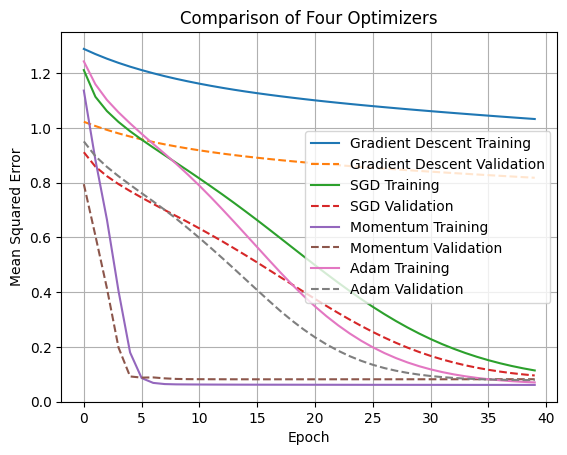

Best Optimizer Based on Final Validation Loss: Adam


In [11]:
np.random.seed(42)
tf.random.set_seed(42)

X = np.random.rand(500, 4).astype("float32")
y = (100 + 50 * X[:, 0] + 30 * X[:, 1]
     + 20 * X[:, 2] + np.random.normal(0, 5, 500)).astype("float32")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

y_mean = y_train.mean()
y_std = y_train.std()

y_train = (y_train - y_mean) / y_std
y_val = (y_val - y_mean) / y_std

optimizers = {
    "Gradient Descent": tf.keras.optimizers.SGD(learning_rate=0.01),
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),
    "Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.001)
}

def create_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

base = create_model()
initial_weights = base.get_weights()

results = {}

for name, optimizer in optimizers.items():
    model = create_model()
    model.set_weights(initial_weights)

    model.compile(optimizer=optimizer, loss="mse")

    batch = len(X_train) if name == "Gradient Descent" else 32

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=batch,
        verbose=0
    )

    results[name] = {
        "train": np.array(history.history["loss"]),
        "val": np.array(history.history["val_loss"])
    }

for name, values in results.items():
    print(f"{name}:")
    print("Final Training Loss:", round(values["train"][-1], 4))
    print("Final Validation Loss:", round(values["val"][-1], 4))

    plt.plot(values["train"], label=f"{name} Training")
    plt.plot(values["val"], linestyle="--", label=f"{name} Validation")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of Four Optimizers")
plt.legend()
plt.grid()
plt.show()

best_optimizer = min(
    results, key=lambda name: results[name]["val"][-1]
)

print("Best Optimizer Based on Final Validation Loss:", best_optimizer)